# Train A1 and A2 aeration airflow forecasts

Use notebook 01's observed-only seven-day, 20-minute aggregate to forecast `Q_A1_air` and `Q_A2_air` one hour ahead. Audit the checked **A1 Aeration Flow** and **A2 Aeration Flow** inputs in `Sensor_Configurations.xlsx` against the application configurations.

The workbook selects **nine A1 inputs and ten A2 inputs**. Following notebook 03, add the stream's current measured airflow as a separately identified autoregressive input, giving **10 A1 and 11 A2 model inputs**. The current target is not presented as a workbook-checked feature. These are forecasts of recorded airflow, not optimized aeration setpoints.

Use the same purged chronological 80/20 split, XGBoost, Random Forest, Extra Trees, scaled Ridge, persistence baseline, comparison tables and timelines as notebooks 03/04. Errors use the workbook's stated **m³/min**. Data timestamps are completed bin-end availability times; no future targets are interpolated. The seven-day completeness-selected experiment is for demonstration and requires an independent later test period before deployment.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
import xgboost
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "config" / "sensors.py").is_file()), None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch from the repository root or notebooks directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.a1_air_flow import CONFIG as A1_CONFIG
from config.a2_air_flow import CONFIG as A2_CONFIG
MODEL_CONFIGS = {cfg["name"]: cfg for cfg in (A1_CONFIG, A2_CONFIG)}

DATA_PATH = PROJECT_ROOT / "notebooks/data/data_filled_20min.csv"
COUNTS_PATH = PROJECT_ROOT / "notebooks/data/data_filled_20min_observed_counts.csv"
OUTPUT_DIR = PROJECT_ROOT / "notebooks/data/aeration_flow_training_20min"
CADENCE = pd.Timedelta(minutes=20)
FORECAST_HORIZON = pd.Timedelta(hours=1)
TRAIN_FRACTION = 0.80
XGB_PARAMETERS = {
    "objective": "reg:squarederror", "n_estimators": 300,
    "learning_rate": 0.03, "max_depth": 3, "min_child_weight": 2,
    "subsample": 0.85, "colsample_bytree": 0.8,
    "reg_alpha": 0.0, "reg_lambda": 2.0,
    "random_state": 42, "n_jobs": 1, "tree_method": "hist",
}


## Audit workbook-selected inputs

Read the Excel workbook with standard ZIP/XML libraries, resolve full tags through `config.sensors`, and require the checked external inputs to match each application configuration. The audit also lists current airflow as an **additional, unchecked autoregressive input**, keeping it distinct from workbook selections. Stop on configuration drift.


In [2]:
from zipfile import ZipFile
import xml.etree.ElementTree as ET
from config.sensors import SENSORS

WORKBOOK_PATH = PROJECT_ROOT / "Sensor_Configurations.xlsx"
NS = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
with ZipFile(WORKBOOK_PATH) as archive:
    shared = []
    if "xl/sharedStrings.xml" in archive.namelist():
        shared = ["".join(item.itertext()) for item in
                  ET.fromstring(archive.read("xl/sharedStrings.xml")).findall("m:si", NS)]
    workbook_rows = []
    for path in archive.namelist():
        if not (path.startswith("xl/worksheets/sheet") and path.endswith(".xml")):
            continue
        rows = []
        for row in ET.fromstring(archive.read(path)).findall(".//m:sheetData/m:row", NS):
            values = {}
            for cell in row.findall("m:c", NS):
                column = "".join(char for char in cell.attrib["r"] if char.isalpha())
                value = cell.find("m:v", NS)
                inline = cell.find("m:is", NS)
                text = value.text if value is not None else "".join(inline.itertext()) if inline is not None else ""
                if cell.get("t") == "s":
                    text = shared[int(text)]
                values[column] = (text or "").strip()
            rows.append(values)
        if any("A1 Aeration Flow" in row.values() for row in rows):
            workbook_rows.extend(rows)
if not workbook_rows:
    raise ValueError("Cannot find aeration input selections in the workbook.")
headers = next(row for row in workbook_rows if "A1 Aeration Flow" in row.values())
feature_headers = {value: column for column, value in headers.items()}
sensor_headers = next(row for row in workbook_rows if "Full Tag Name" in row.values())
tag_column = next(column for column, value in sensor_headers.items() if value == "Full Tag Name")
alias_by_tag = {sensor["fullTagName"].casefold(): alias for alias, sensor in SENSORS.items()}
feature_audit_records = []
for cfg, heading in [(A1_CONFIG, "A1 Aeration Flow"), (A2_CONFIG, "A2 Aeration Flow")]:
    checked = []
    for row in workbook_rows:
        mark = row.get(feature_headers[heading], "")
        if not mark or mark == heading:
            continue
        tag = row.get(tag_column, "").casefold()
        if not tag:
            continue
        if mark != "✓":
            raise ValueError(f"Unknown workbook selection mark: {mark!r}")
        if tag not in alias_by_tag:
            raise ValueError(f"Unmapped checked workbook tag: {tag}")
        alias = alias_by_tag[tag]
        checked.append(alias)
        feature_audit_records.append({
            "model": cfg["name"], "checked_alias": alias, "full_tag": tag,
            "role": "workbook-checked input", "workbook_checked": True,
        })
    if len(checked) != len(set(checked)) or cfg["target"] in checked:
        raise ValueError("Checked external inputs must be unique and exclude the current aeration target.")
    expected = set(cfg["features"])
    if set(checked) != expected:
        raise ValueError(f"Workbook/config mismatch for {cfg['name']}: {set(checked) ^ expected}")
    feature_audit_records.append({
        "model": cfg["name"], "checked_alias": cfg["target"],
        "full_tag": SENSORS[cfg["target"]]["fullTagName"],
        "role": "additional current-airflow autoregressive input", "workbook_checked": False,
    })
    # Preserve workbook feature order; the split cell separately adds current airflow.
    MODEL_CONFIGS[cfg["name"]] = {
        **cfg, "features": [alias for alias in checked if alias != cfg["target"]],
    }
feature_audit = pd.DataFrame(feature_audit_records)
display(feature_audit)
print("Verified 9 A1 and 10 A2 workbook inputs; current airflow adds one input per model.")


,model,checked_alias,full_tag,role,workbook_checked
0,a1_air_flow,A1_Qin,70flowa1qin,workbook-checked input,True
1,a1_air_flow,A1_FQ_CH3OH,70flowa1methdosing,workbook-checked input,True
2,a1_air_flow,A1_Q_r1,70flowa1internalrecycle,workbook-checked input,True
3,a1_air_flow,A1_NH3_N,70nh3_na1nh3n,workbook-checked input,True
4,a1_air_flow,A1_O_PH,70pha1aerobic,workbook-checked input,True
5,a1_air_flow,A1_O_ORP,70orpa1aerobic,workbook-checked input,True
6,a1_air_flow,A1_O_DO,70doa1aerobic,workbook-checked input,True
7,a1_air_flow,A1_O_MLSS,70mlssa1aerobic,workbook-checked input,True
8,a1_air_flow,Q_A2_air,70flowa2aerobic,workbook-checked input,True
9,a1_air_flow,Q_A1_air,70flowa1aerobic,additional current-airflow autoregressive input,False


Verified 9 A1 and 10 A2 workbook inputs; current airflow adds one input per model.


## Validate source data and observation support

CSV columns use configured SQL aliases. The aggregate contains raw observations only, so a minute-level interpolation mask does not apply. Its companion counts record actual readings contributing to each bin. Require a regular timeline, complete numeric values, and positive observation counts. Keep the 20-minute resolution instead of upsampling it into artificial ten-minute observations.


In [3]:
data = pd.read_csv(DATA_PATH, encoding="utf-8-sig", index_col="available_at", parse_dates=True)
observed_counts = pd.read_csv(COUNTS_PATH, index_col="available_at", parse_dates=True)
if data.empty or not isinstance(data.index, pd.DatetimeIndex):
    raise ValueError("Expected nonempty data indexed by bin-end availability timestamps.")
if not data.index.is_unique or not data.index.is_monotonic_increasing:
    raise ValueError("Timestamps must be unique and increasing.")
if not data.index.to_series().diff().dropna().eq(CADENCE).all():
    raise ValueError("The input must be a continuous 20-minute timeline.")
if not data.index.equals(observed_counts.index) or list(data.columns) != list(observed_counts.columns):
    raise ValueError("Observed counts and data must align exactly.")
data = data.apply(pd.to_numeric, errors="raise")
if not np.isfinite(data.to_numpy()).all() or not observed_counts.ge(1).all().all():
    raise ValueError("Expected finite observed means with positive support for every bin.")
if not 0 < TRAIN_FRACTION < 1 or FORECAST_HORIZON % CADENCE:
    raise ValueError("Invalid train fraction or horizon/cadence combination.")
for name, cfg in MODEL_CONFIGS.items():
    missing = set(cfg["features"] + [cfg["target"]]) - set(data.columns)
    if missing:
        raise ValueError(f"{name} missing configured columns: {missing}")
print(f"Loaded {len(data)} bins × {len(data.columns)} sensors.")
print(f"Available at: {data.index.min()} through {data.index.max()}")
print(f"Minimum raw readings per sensor/bin: {observed_counts.min().min()}")
display(data[[A1_CONFIG["target"], A2_CONFIG["target"]]].describe())


Loaded 504 bins × 30 sensors.
Available at: 2026-04-03 23:05:00 through 2026-04-10 22:45:00
Minimum raw readings per sensor/bin: 5


,Q_A1_air,Q_A2_air
count,504.000000,504.000000
mean,49.552594,41.112261
std,1.913637,2.131452
min,24.213400,17.677000
25%,48.849163,39.882800
50%,49.818771,41.319129
75%,50.535326,42.596566
max,52.105975,43.996750


## Build future labels and purge the chronological split

Use configured current-bin features plus the model's current aeration flow measurement as an autoregressive input. Match the future target by **timestamp** exactly one hour later. Observation counts are diagnostics, not additional model inputs.

Training labels must end no later than the first test forecast origin. This permits a label that becomes available exactly at that origin, before issuing its forecast. Test predictions use newly available current observations sequentially; this is rolling one-hour-ahead evaluation, not a single fixed-origin forecast of the entire test period.


In [4]:
splits = {}
model_datasets = {}
split_records = []
for name, cfg in MODEL_CONFIGS.items():
    target = cfg["target"]
    current_column = f"{target}__current"
    frame = data[cfg["features"]].copy()
    frame[current_column] = data[target]
    label_times = frame.index + FORECAST_HORIZON
    frame["future_target"] = data[target].reindex(label_times).to_numpy()
    frame = frame.loc[frame["future_target"].notna()].copy()
    split_position = int(len(frame) * TRAIN_FRACTION)
    if not 1 <= split_position < len(frame):
        raise ValueError("Not enough data for a chronological split.")
    test = frame.iloc[split_position:].copy()
    first_test_origin = test.index.min()
    train = frame.iloc[:split_position].copy()
    train = train.loc[train.index + FORECAST_HORIZON <= first_test_origin]
    if train.empty or len(test) < 2:
        raise ValueError("Insufficient rows after purging.")
    inputs = [*cfg["features"], current_column]
    assert train.index.max() + FORECAST_HORIZON <= test.index.min()
    assert train.index.intersection(test.index).empty
    splits[name] = {
        "X_train": train[inputs], "y_train": train["future_target"],
        "X_test": test[inputs], "y_test": test["future_target"],
        "current_column": current_column,
    }
    model_datasets[name] = frame
    split_records.append({
        "model": name, "target": target, "inputs": len(inputs),
        "train_rows": len(train), "test_rows": len(test),
        "purged_rows": split_position - len(train),
        "first_train_origin": train.index.min(), "last_train_origin": train.index.max(),
        "last_train_label_available": train.index.max() + FORECAST_HORIZON,
        "first_test_origin": test.index.min(), "last_test_origin": test.index.max(),
        "last_test_label_available": test.index.max() + FORECAST_HORIZON,
        "train_target_unique": train["future_target"].nunique(),
        "test_target_unique": test["future_target"].nunique(),
    })
split_summary = pd.DataFrame(split_records).set_index("model")
display(split_summary)


,target,inputs,train_rows,test_rows,purged_rows,first_train_origin,last_train_origin,last_train_label_available,first_test_origin,last_test_origin,last_test_label_available,train_target_unique,test_target_unique
model,,,,,,,,,,,,,
a1_air_flow,Q_A1_air,10,398,101,2,2026-04-03 23:05:00,2026-04-09 11:25:00,2026-04-09 12:25:00,2026-04-09 12:25:00,2026-04-10 21:45:00,2026-04-10 22:45:00,398,101
a2_air_flow,Q_A2_air,11,398,101,2,2026-04-03 23:05:00,2026-04-09 11:25:00,2026-04-09 12:25:00,2026-04-09 12:25:00,2026-04-10 21:45:00,2026-04-10 22:45:00,398,101


## Fit both models and compare with persistence

Use fixed parameters without tuning on the held-out test period. Report MAE, RMSE, bias and R² in the original target units. R² is undefined for constant actual targets. A positive skill score means lower error than persistence; skill is undefined when the baseline error is zero. Constant targets, if present, cannot establish skill at forecasting operational changes.


In [5]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "N": len(actual),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(mean_squared_error(actual, predicted) ** 0.5),
        "Bias": float(np.mean(predicted - actual)),
        "R2": float(r2_score(actual, predicted)) if np.unique(actual).size > 1 else np.nan,
    }

models = {}
predictions = {}
metric_records = []
importance_tables = {}
for name, split in splits.items():
    model = XGBRegressor(**XGB_PARAMETERS)
    model.fit(split["X_train"], split["y_train"])
    models[name] = model
    results = pd.DataFrame({
        "forecast_origin": split["X_test"].index,
        "target_available_at": split["X_test"].index + FORECAST_HORIZON,
        "actual": split["y_test"].to_numpy(),
        "xgboost": model.predict(split["X_test"]),
        "persistence": split["X_test"][split["current_column"]].to_numpy(),
    }).set_index("forecast_origin")
    predictions[name] = results
    baseline = regression_metrics(results["actual"], results["persistence"])
    for estimator in ("xgboost", "persistence"):
        metrics = regression_metrics(results["actual"], results[estimator])
        for metric in ("MAE", "RMSE"):
            metrics[f"{metric}_skill_pct"] = (
                100 * (1 - metrics[metric] / baseline[metric])
                if baseline[metric] > 0 else np.nan
            )
        metric_records.append({"model": name, "estimator": estimator, **metrics})
    importance_tables[name] = pd.DataFrame({
        "feature": split["X_train"].columns, "importance": model.feature_importances_,
    }).sort_values("importance", ascending=False)
    if split["y_train"].nunique() == 1:
        print(f"{name}: training target is constant; persistence is the meaningful reference.")
metrics_table = pd.DataFrame(metric_records).set_index(["model", "estimator"])
display(metrics_table.style.format(precision=6, na_rep="undefined"))
for name, importance in importance_tables.items():
    print(name, "top fitted feature importances (not causal effects)")
    display(importance.head(10))


a1_air_flow top fitted feature importances (not causal effects)


,feature,importance
9,Q_A1_air__current,0.517826
8,Q_A2_air,0.308333
1,A1_FQ_CH3OH,0.040542
4,A1_O_PH,0.031634
7,A1_O_MLSS,0.031208
5,A1_O_ORP,0.027102
6,A1_O_DO,0.018079
2,A1_Q_r1,0.014731
0,A1_Qin,0.010545
3,A1_NH3_N,0.000000


a2_air_flow top fitted feature importances (not causal effects)


,feature,importance
10,Q_A2_air__current,0.556935
1,A2_COD_in,0.176616
6,A2_O_ORP,0.061289
3,A2_FQ_CH3OH,0.061237
2,A2_Q_r1,0.047862
5,A2_O_PH,0.037748
8,A2_O_MLSS,0.021778
0,A2_Qin,0.016056
9,Eff_NH4_N,0.010294
7,A2_O_DO,0.010187


## Test-set actual versus predicted values

Compare the observed test targets with XGBoost predictions at the same future target bin-end timestamps. Each target has one time-series plot. For a constant target, the actual and predicted series may overlap.


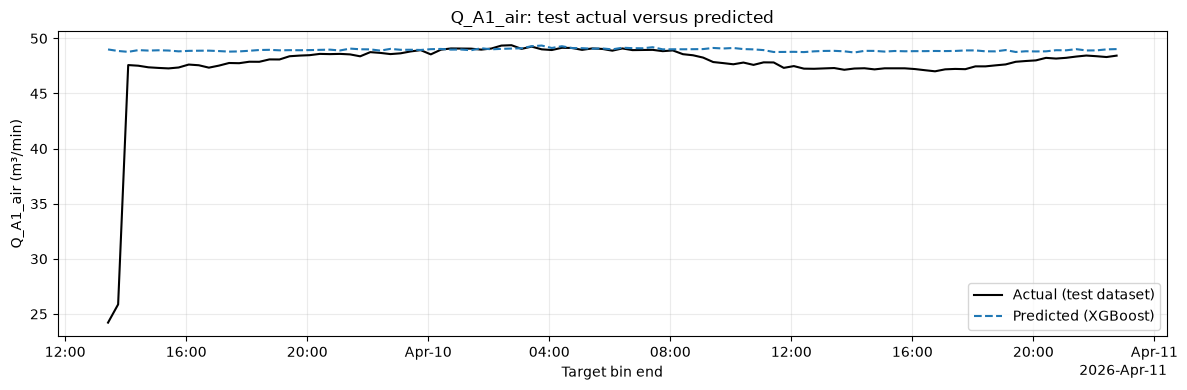

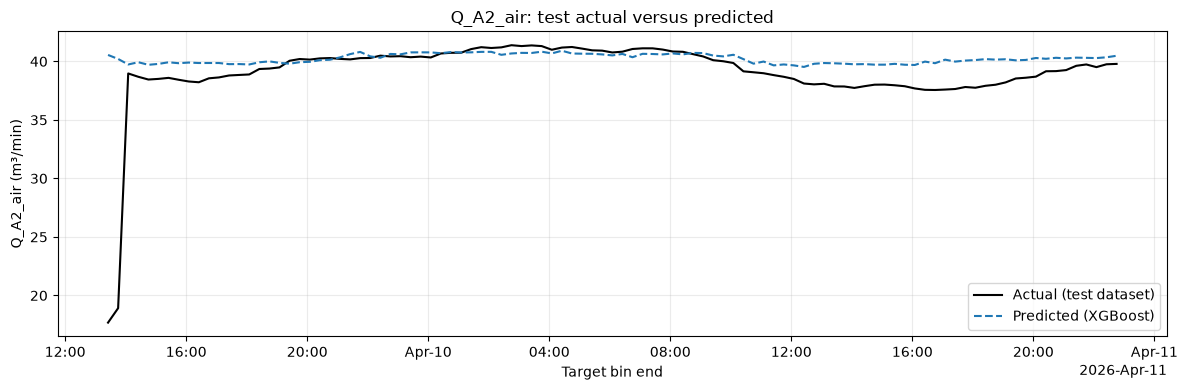

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, cfg in MODEL_CONFIGS.items():
    results = predictions[name]
    target_times = results["target_available_at"]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(target_times, results["actual"], color="black", linewidth=1.5,
            label="Actual (test dataset)")
    ax.plot(target_times, results["xgboost"], color="tab:blue", linewidth=1.5,
            linestyle="--", label="Predicted (XGBoost)")
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end", ylabel=f"{cfg['target']} (m³/min)",
           title=f"{cfg['target']}: test actual versus predicted")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_evaluation.png", dpi=150, bbox_inches="tight")
    plt.show()


## Training, test and prediction overview

Show observed training targets, observed test targets and held-out predictions together. Green shading marks training labels, amber marks labels removed by horizon purging, and blue marks test labels. All readings are plotted at their **target bin-end timestamp**, one hour after their forecast origin; the dashed boundary marks the first test target. It is therefore one hour later than the first test forecast origin shown in the split table. No fitted training predictions are included.


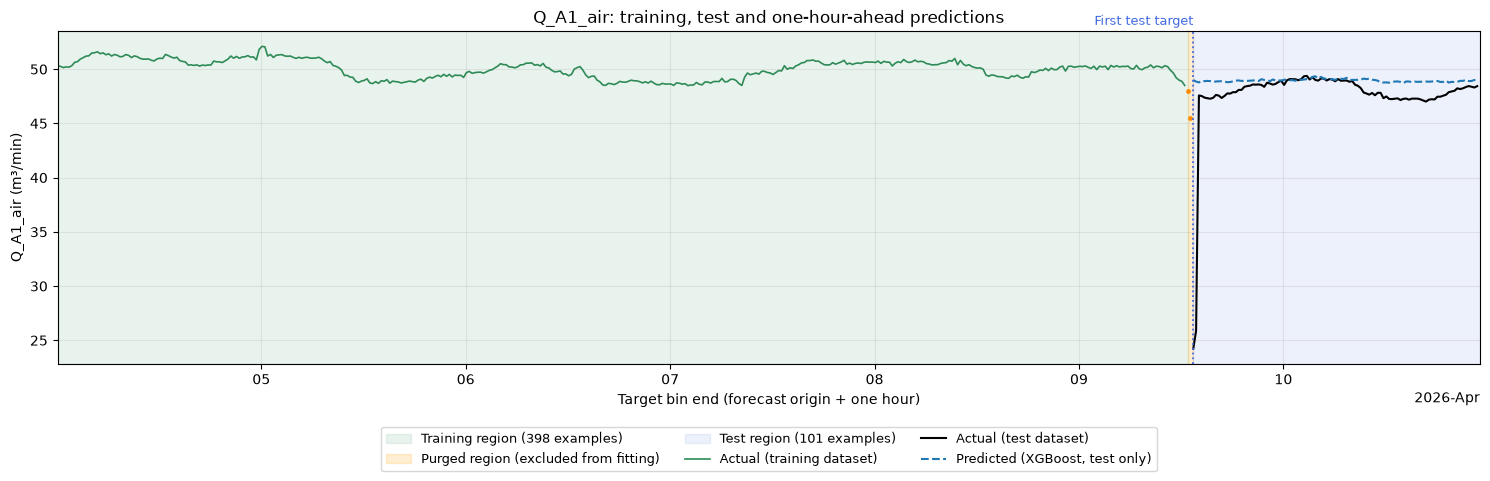

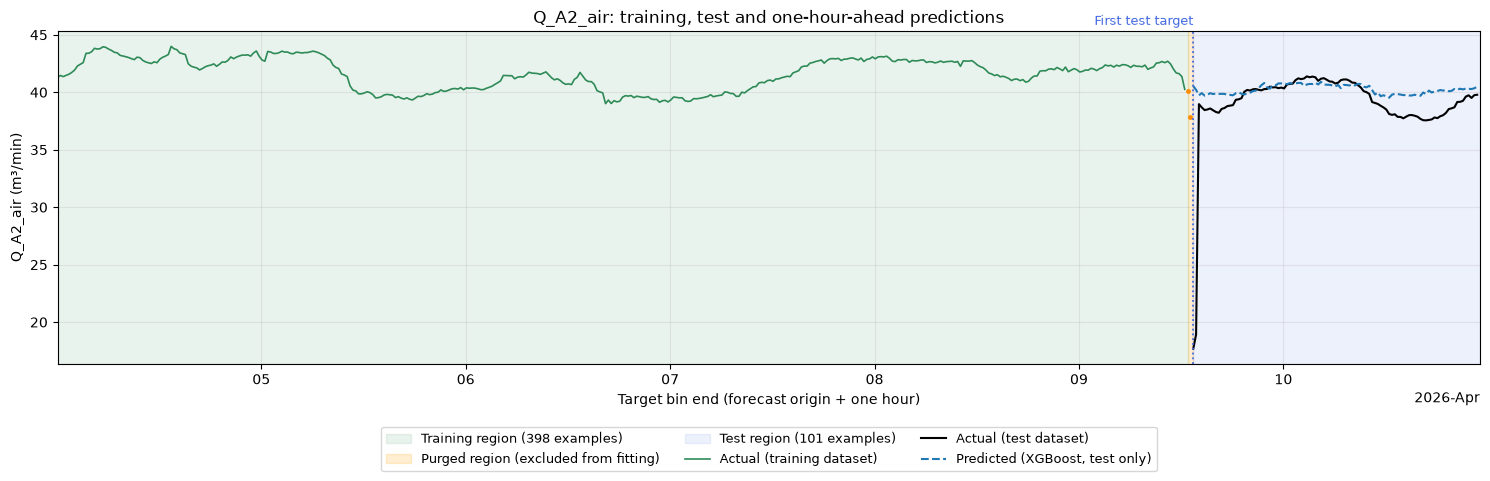

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, cfg in MODEL_CONFIGS.items():
    train_actual = splits[name]["y_train"]
    results = predictions[name]
    train_times = train_actual.index + FORECAST_HORIZON
    test_times = pd.DatetimeIndex(results["target_available_at"])
    train_region_end = train_times.max() + CADENCE
    test_region_start = test_times.min()
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.axvspan(train_times.min(), train_region_end, color="seagreen", alpha=0.10,
               label=f"Training region ({len(train_actual)} examples)")
    if train_region_end < test_region_start:
        ax.axvspan(train_region_end, test_region_start, color="orange", alpha=0.18,
                   label="Purged region (excluded from fitting)")
        excluded = model_datasets[name]["future_target"]
        excluded_times = excluded.index + FORECAST_HORIZON
        purged = (excluded_times >= train_region_end) & (excluded_times < test_region_start)
        ax.plot(excluded_times[purged], excluded.loc[purged], ".", color="darkorange",
                markersize=5)
    ax.axvspan(test_region_start, test_times.max() + CADENCE,
               color="royalblue", alpha=0.09,
               label=f"Test region ({len(results)} examples)")
    ax.plot(train_times, train_actual, color="seagreen", linewidth=1.2,
            label="Actual (training dataset)")
    ax.plot(test_times, results["actual"], color="black", linewidth=1.5,
            label="Actual (test dataset)")
    ax.plot(test_times, results["xgboost"], color="tab:blue", linestyle="--",
            linewidth=1.5, label="Predicted (XGBoost, test only)")
    ax.axvline(test_region_start, color="royalblue", linestyle=":", linewidth=1.3)
    ax.text(test_region_start, 1.01, "First test target", transform=ax.get_xaxis_transform(),
            color="royalblue", fontsize=9, ha="right", va="bottom")
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end (forecast origin + one hour)",
           ylabel=f"{cfg['target']} (m³/min)",
           title=f"{cfg['target']}: training, test and one-hour-ahead predictions")
    ax.set_xlim(train_times.min(), test_times.max() + CADENCE)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_train_test_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


## Save models, predictions and reproducibility information

Save the evaluated training-only models (no refit on test data), metrics, split dates, feature importances and source hashes in `notebooks/data/aeration airflow_training_20min/`. Rerunning replaces these local files. The data directory is ignored by Git. Model metadata defines the availability timestamps, input feature order, cadence and horizon needed to interpret predictions.


In [8]:
feature_audit.to_csv(OUTPUT_DIR / "workbook_feature_audit.csv", index=False)
metrics_table.to_csv(OUTPUT_DIR / "metrics.csv")
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv")
for name, model in models.items():
    model.save_model(OUTPUT_DIR / f"{name}.ubj")
    predictions[name].to_csv(OUTPUT_DIR / f"{name}_test_predictions.csv")
    importance_tables[name].to_csv(OUTPUT_DIR / f"{name}_feature_importance.csv", index=False)
metadata = {
    "data_path": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "workbook_sha256": hashlib.sha256(WORKBOOK_PATH.read_bytes()).hexdigest(),
    "target_units": "m3/min",
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "observed_counts_sha256": hashlib.sha256(COUNTS_PATH.read_bytes()).hexdigest(),
    "source_interval_start_inclusive": str(data.index.min() - CADENCE),
    "source_interval_end_exclusive": str(data.index.max()),
    "cadence": str(CADENCE), "forecast_horizon": str(FORECAST_HORIZON),
    "timestamp_semantics": "bin-end availability; future label ends origin + horizon",
    "train_fraction_before_purge": TRAIN_FRACTION,
    "parameters": XGB_PARAMETERS,
    "features": {name: list(split["X_train"].columns) for name, split in splits.items()},
    "targets": {name: cfg["target"] for name, cfg in MODEL_CONFIGS.items()},
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "xgboost": xgboost.__version__,
                 "scikit_learn": sklearn.__version__},
    "limitations": ["single seven-day completeness-selected window", "no hyperparameter tuning",
                    "requires independent later-period validation"],
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
# Check that saved models reproduce held-out predictions.
for name in models:
    restored = XGBRegressor()
    restored.load_model(OUTPUT_DIR / f"{name}.ubj")
    np.testing.assert_allclose(restored.predict(splits[name]["X_test"]),
                               predictions[name]["xgboost"], rtol=1e-6)
print(f"Saved and verified both models and evaluation artifacts in {OUTPUT_DIR}")


Saved and verified both models and evaluation artifacts in /home/bryan1010/projects/ao-mbr-data-pipeline/notebooks/data/aeration_flow_training_20min


## Compare forecasting algorithms

Compare **Ridge regression** (a regularized linear reference), **Random Forest** (averaged decision trees), and **Extra Trees** (more randomized trees) with XGBoost and persistence. These supervised regressors use exactly the same configured sensor inputs, current target, one-hour labels and purged chronological split. Ridge scaling is fitted inside its training-only pipeline. Fixed settings are used without tuning on the test set.

This is a demonstration comparison on one small holdout, not independent confirmation of the best algorithm. Comparing models repeatedly on this test set makes it unsuitable as the final unbiased evaluation set. Use a separate later period before model selection or deployment. A constant target, if present, cannot establish forecasting skill.

References: [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), [Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).


In [9]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib

ESTIMATOR_LABELS = {
    "xgboost": "XGBoost", "random_forest": "Random Forest",
    "extra_trees": "Extra Trees", "ridge": "Ridge", "persistence": "Persistence",
}
ESTIMATOR_COLORS = {
    "xgboost": "tab:blue", "random_forest": "tab:purple",
    "extra_trees": "tab:red", "ridge": "tab:orange",
}
comparison_models = {}
comparison_predictions = {}
comparison_records = []
for name, split in splits.items():
    fitted = {"xgboost": models[name]}
    candidates = {
        "random_forest": RandomForestRegressor(
            n_estimators=300, max_depth=6, min_samples_leaf=3,
            random_state=42, n_jobs=1,
        ),
        "extra_trees": ExtraTreesRegressor(
            n_estimators=300, max_depth=6, min_samples_leaf=3,
            random_state=42, n_jobs=1,
        ),
        "ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    }
    results = predictions[name].copy()
    for key, estimator in candidates.items():
        estimator.fit(split["X_train"], split["y_train"])
        results[key] = estimator.predict(split["X_test"])
        fitted[key] = estimator
    comparison_models[name] = fitted
    comparison_predictions[name] = results
    reference = regression_metrics(results["actual"], results["persistence"])
    for key, label in ESTIMATOR_LABELS.items():
        metrics = regression_metrics(results["actual"], results[key])
        for metric in ("MAE", "RMSE"):
            metrics[f"{metric}_skill_pct"] = (
                100 * (1 - metrics[metric] / reference[metric])
                if reference[metric] > 0 else np.nan
            )
        comparison_records.append({"target": name, "algorithm": label, **metrics})
comparison_metrics = pd.DataFrame(comparison_records).set_index(["target", "algorithm"])
for name in MODEL_CONFIGS:
    print(name, "— identical held-out observations for every algorithm")
    display(comparison_metrics.loc[name].sort_values("MAE", kind="stable")
            .style.format(precision=6, na_rep="undefined"))
print("Lower MAE/RMSE is better; positive skill beats persistence; constant-target R² is undefined.")


a1_air_flow — identical held-out observations for every algorithm


,N,MAE,RMSE,Bias,R2,MAE_skill_pct,RMSE_skill_pct
algorithm,,,,,,,
Ridge,101,1.065055,4.308739,0.069098,-0.712143,4.455706,5.401681
Persistence,101,1.114724,4.554773,-0.031318,-0.913257,0.000000,0.000000
Random Forest,101,1.262635,3.506305,1.207938,-0.133807,-13.268856,23.019111
Extra Trees,101,1.280485,3.511857,1.266757,-0.137401,-14.870205,22.897210
XGBoost,101,1.290958,3.511207,1.270293,-0.136979,-15.809653,22.911493


a2_air_flow — identical held-out observations for every algorithm


,N,MAE,RMSE,Bias,R2,MAE_skill_pct,RMSE_skill_pct
algorithm,,,,,,,
Ridge,101,1.120780,4.094668,0.081435,-0.644635,3.188534,2.944400
Persistence,101,1.157694,4.218889,-0.008503,-0.745936,0.000000,0.000000
Random Forest,101,1.181034,3.221573,0.902176,-0.018048,-2.016064,23.639304
Extra Trees,101,1.288590,3.294573,1.142264,-0.064708,-11.306623,21.908993
XGBoost,101,1.349525,3.316129,1.144688,-0.078686,-16.570146,21.398052


Lower MAE/RMSE is better; positive skill beats persistence; constant-target R² is undefined.


## Model comparison over time: test dataset

Use the same test-only timeline format as above: actual target values and all four model predictions, aligned to future bin ends. Persistence remains in the metrics table as the reference. If a target is constant, model lines may overlap.


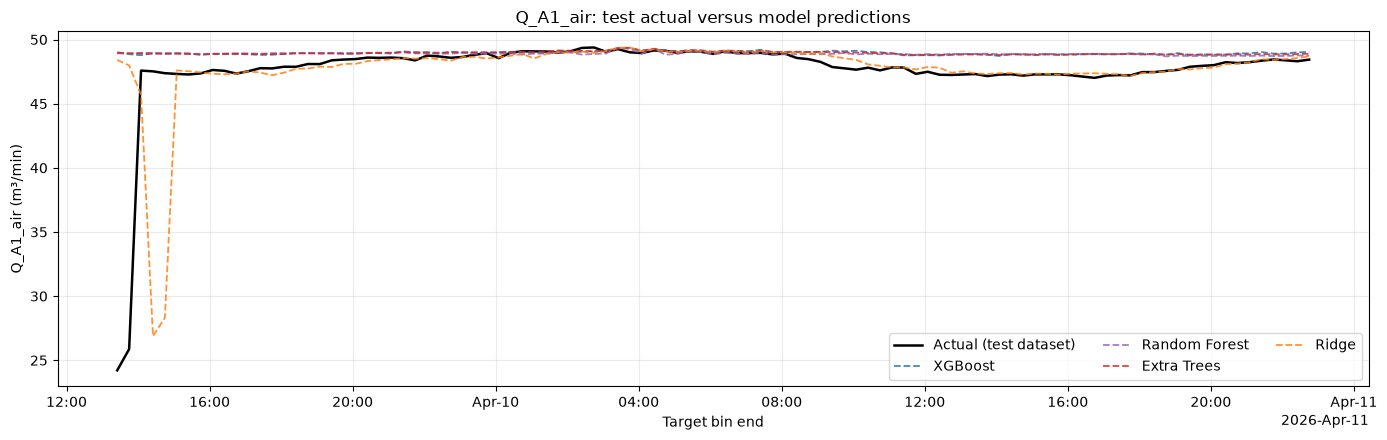

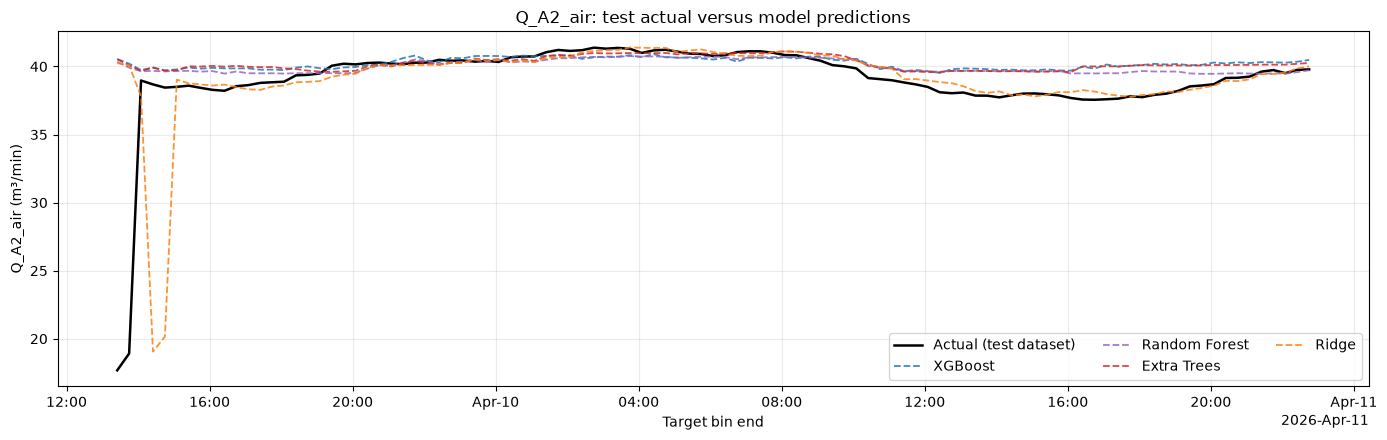

In [10]:
for name, cfg in MODEL_CONFIGS.items():
    results = comparison_predictions[name]
    times = results["target_available_at"]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(times, results["actual"], color="black", linewidth=1.8,
            label="Actual (test dataset)")
    for key, color in ESTIMATOR_COLORS.items():
        ax.plot(times, results[key], color=color, linewidth=1.3,
                linestyle="--", alpha=0.85, label=ESTIMATOR_LABELS[key])
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end", ylabel=f"{cfg['target']} (m³/min)",
           title=f"{cfg['target']}: test actual versus model predictions")
    ax.grid(True, alpha=0.25)
    ax.legend(ncol=3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_algorithm_comparison_test.png", dpi=150, bbox_inches="tight")
    plt.show()


## Model comparison with highlighted train/test regions

Keep the same target-time axis and training/purge/test shading as the earlier overview. Plot only held-out model predictions; the green actual series supplies the training context. The test boundary marks the first test **target**, one hour after the first forecast origin.


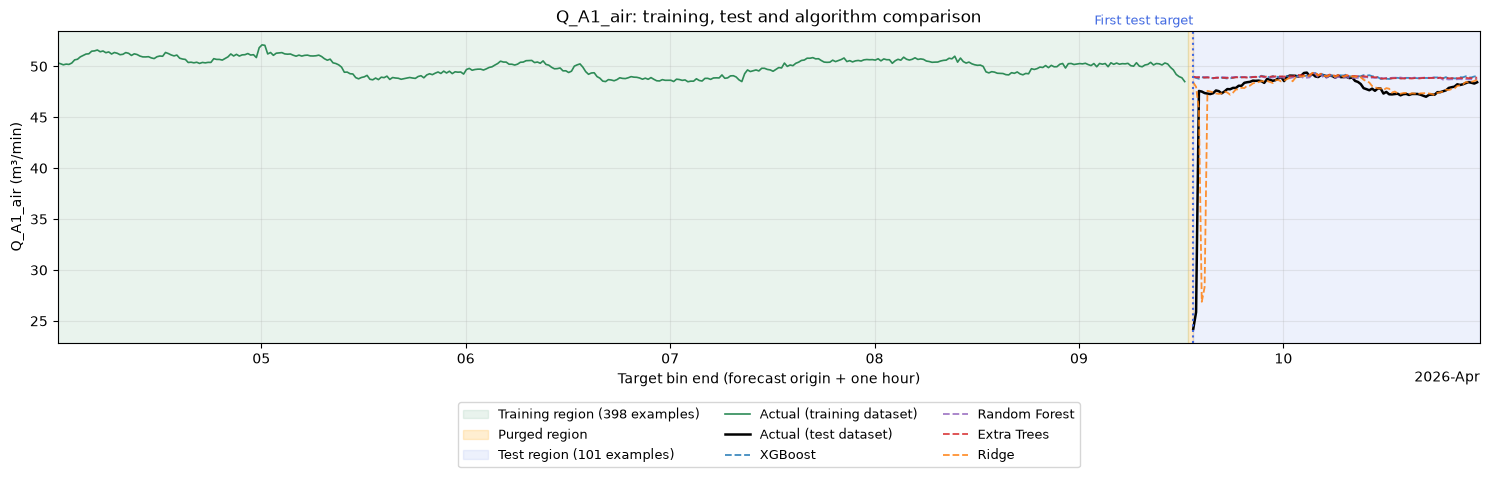

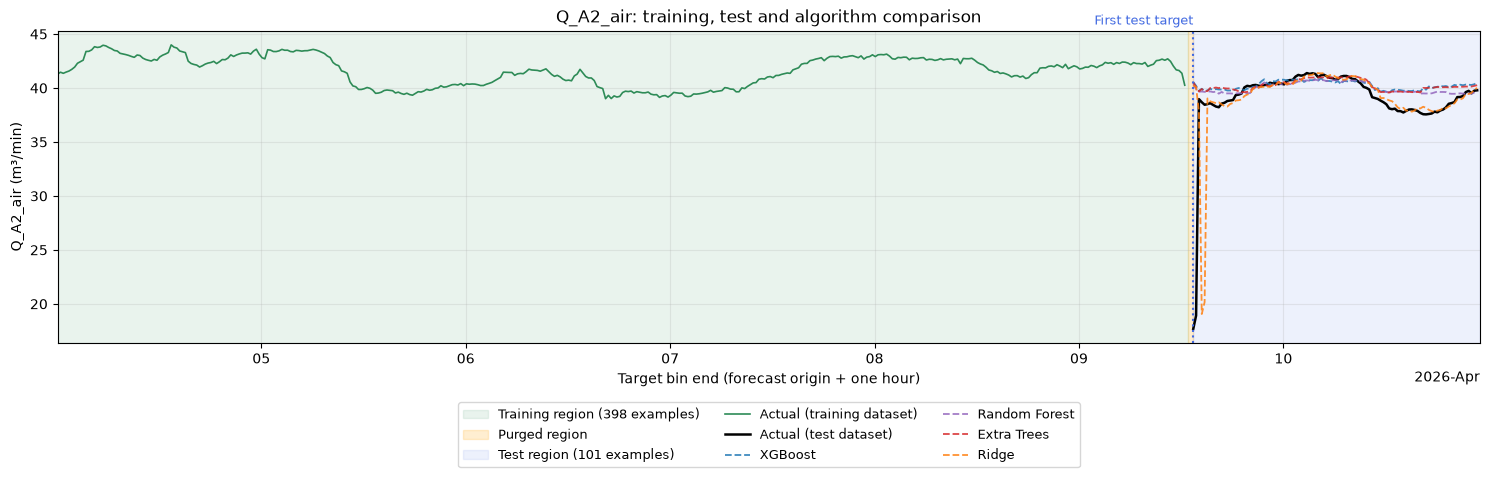

In [11]:
for name, cfg in MODEL_CONFIGS.items():
    results = comparison_predictions[name]
    actual_train = splits[name]["y_train"]
    train_times = actual_train.index + FORECAST_HORIZON
    test_times = pd.DatetimeIndex(results["target_available_at"])
    train_end = train_times.max() + CADENCE
    test_start = test_times.min()
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.axvspan(train_times.min(), train_end, color="seagreen", alpha=0.10,
               label=f"Training region ({len(actual_train)} examples)")
    if train_end < test_start:
        ax.axvspan(train_end, test_start, color="orange", alpha=0.18,
                   label="Purged region")
    ax.axvspan(test_start, test_times.max() + CADENCE, color="royalblue", alpha=0.09,
               label=f"Test region ({len(results)} examples)")
    ax.plot(train_times, actual_train, color="seagreen", linewidth=1.2,
            label="Actual (training dataset)")
    ax.plot(test_times, results["actual"], color="black", linewidth=1.8,
            label="Actual (test dataset)")
    for key, color in ESTIMATOR_COLORS.items():
        ax.plot(test_times, results[key], color=color, linewidth=1.3,
                linestyle="--", alpha=0.85, label=ESTIMATOR_LABELS[key])
    ax.axvline(test_start, color="royalblue", linestyle=":")
    ax.text(test_start, 1.01, "First test target", transform=ax.get_xaxis_transform(),
            ha="right", va="bottom", color="royalblue", fontsize=9)
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end (forecast origin + one hour)",
           ylabel=f"{cfg['target']} (m³/min)",
           title=f"{cfg['target']}: training, test and algorithm comparison")
    ax.set_xlim(train_times.min(), test_times.max() + CADENCE)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_algorithm_comparison_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


## Save comparison results

Save the table, shared test predictions, model parameters and fitted estimators. Models retain the original training-only fit. Reload each additional estimator and check that its predictions are unchanged. Joblib files are local artifacts; only load files from trusted sources.


In [12]:
comparison_metrics.to_csv(OUTPUT_DIR / "algorithm_comparison_metrics.csv")
comparison_parameters = {}
for name, fitted in comparison_models.items():
    comparison_predictions[name].to_csv(OUTPUT_DIR / f"{name}_algorithm_comparison_predictions.csv")
    comparison_parameters[name] = {}
    for key, estimator in fitted.items():
        comparison_parameters[name][key] = estimator.get_params(deep=True)
        if key != "xgboost":
            path = OUTPUT_DIR / f"{name}_{key}.joblib"
            joblib.dump(estimator, path)
            restored = joblib.load(path)
            np.testing.assert_allclose(restored.predict(splits[name]["X_test"]),
                                       comparison_predictions[name][key], rtol=1e-6)
(OUTPUT_DIR / "algorithm_comparison_parameters.json").write_text(
    json.dumps(comparison_parameters, indent=2, default=str) + "\n"
)
print(f"Saved comparison metrics, predictions, plots and verified models in {OUTPUT_DIR}")


Saved comparison metrics, predictions, plots and verified models in /home/bryan1010/projects/ao-mbr-data-pipeline/notebooks/data/aeration_flow_training_20min


## Results from this execution

Workbook audit confirmed **nine A1 and ten A2 checked features**, plus one separately identified current-airflow autoregressive input per model. Both streams use **398 training and 101 test examples**, with two boundary origins purged.

| Stream | Algorithm | MAE (m³/min) | RMSE (m³/min) | R² |
|---|---|---:|---:|---:|
| A1 | XGBoost | 1.290958 | 3.511207 | -0.136979 |
| A1 | Random Forest | 1.262635 | 3.506305 | -0.133807 |
| A1 | Extra Trees | 1.280485 | 3.511857 | -0.137401 |
| A1 | Ridge | 1.065055 | 4.308739 | -0.712143 |
| A1 | Persistence | 1.114724 | 4.554773 | -0.913257 |
| A2 | XGBoost | 1.349525 | 3.316129 | -0.078686 |
| A2 | Random Forest | 1.181034 | 3.221573 | -0.018048 |
| A2 | Extra Trees | 1.288590 | 3.294573 | -0.064708 |
| A2 | Ridge | 1.120780 | 4.094668 | -0.644635 |
| A2 | Persistence | 1.157694 | 4.218889 | -0.745936 |

Ridge achieves the lowest MAE for both streams: **4.46% better than persistence for A1**, and **3.19% for A2**. Random Forest has the lowest RMSE: **23.02% better than persistence for A1**, and **23.64% for A2**. Different algorithms lead on typical versus large errors; every model still has negative R² on this short holdout. Present these as preliminary demo comparisons rather than established operational accuracy. Validate airflow scaling/units and a separate later period before selecting a model.

All code cells executed successfully. Saved models were reloaded and their test predictions verified. Tables, figures, models, metadata and the workbook audit are saved under `data/aeration_flow_training_20min/`.
